
# Studio Proyek 3 — Fine-Tuning Transformer untuk NLP

## Soal 1: Rancangan Eksperimen

**Dataset:** SmSA (IndoNLU)

**Tujuan:** Membandingkan performa tiga model Transformer pretrained untuk klasifikasi sentimen Bahasa Indonesia (negatif, netral, positif).

### Backbone yang digunakan
1. BERT Multilingual (`bert-base-multilingual-cased`)
2. DistilBERT Multilingual (`distilbert-base-multilingual-cased`)
3. IndoBERT (`indobenchmark/indobert-base-p1`)

### Strategi fine-tuning
1. Full Fine-Tuning
2. Linear Probing

### Matriks eksperimen

| Backbone | Full Fine-Tuning | Linear Probing |
|---|---|---|
| BERT | 3 seed | 3 seed |
| DistilBERT | 3 seed | 3 seed |
| IndoBERT | 3 seed | 3 seed |

Total: **18 run eksperimen**.

### Hyperparameter
- Max length: 128
- Batch size: 16
- Epoch: 3
- Seed: 42, 123, 2026
- Learning rate Full Fine-Tuning: 2e-5
- Learning rate Linear Probing: 1e-3
- Data latih: 3.000 sampel
- Data validasi: minimal 500 sampel
- Data uji: 500 sampel resmi SmSA

### Hipotesis
- **H1:** IndoBERT diperkirakan memberikan Macro-F1 tertinggi.
- **H2:** Full Fine-Tuning diperkirakan menghasilkan Macro-F1 lebih tinggi dibandingkan Linear Probing.
- **H3:** DistilBERT diperkirakan lebih efisien dari BERT dalam waktu pelatihan dan inferensi.

### Alasan pemilihan dataset
SmSA dipilih karena menyediakan teks Bahasa Indonesia dengan tiga kategori sentimen dan memungkinkan perbandingan model multilingual dengan model khusus Bahasa Indonesia.

### Variabel terkendali
Seluruh eksperimen menggunakan dataset, pembagian data, max length, batch size, epoch, dan daftar seed yang sama. Learning rate dibedakan berdasarkan strategi pelatihan.


In [ ]:

import torch

print("PyTorch:", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))





PyTorch: 2.14.1+cu130
GPU tersedia: True
Nama GPU: Tesla T4


In [ ]:
!pip -q install -U transformers datasets accelerate scikit-learn pandas matplotlib seaborn


In [ ]:

import pandas as pd
import requests
from io import StringIO

BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa"

def load_smsa(split):
    url = f"{BASE_URL}/{split}_preprocess.tsv"
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    df = pd.read_csv(
        StringIO(response.text),
        sep="\t",
        header=None,
        names=["text", "label"]
    )
    return df

train_df = load_smsa("train")
valid_df = load_smsa("valid")
test_df = load_smsa("test")

print("Train:", train_df.shape)
print("Valid:", valid_df.shape)
print("Test:", test_df.shape)

display(train_df.head())


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Train: (11000, 2)
Valid: (1260, 2)
Test: (500, 2)


,text,label
0,warung ini dimiliki oleh pengusaha pabrik tahu...,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai...,neutral
2,lokasi strategis di jalan sumatera bandung . t...,positive
3,betapa bahagia nya diri ini saat unboxing pake...,positive
4,duh . jadi mahasiswa jangan sombong dong . kas...,negative


In [ ]:

for name, df in [
    ("Train", train_df),
    ("Valid", valid_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print(df["label"].value_counts())
    print("Total:", len(df))



Train
label
positive    6416
negative    3436
neutral     1148
Name: count, dtype: int64
Total: 11000

Valid
label
positive    735
negative    394
neutral     131
Name: count, dtype: int64
Total: 1260

Test
label
positive    208
negative    204
neutral      88
Name: count, dtype: int64
Total: 500


In [ ]:

import pandas as pd

# Salin dataset asli
train_clean = train_df.copy()
valid_clean = valid_df.copy()

# Normalisasi teks untuk pemeriksaan duplikat
for df in [train_clean, valid_clean]:
    df["text"] = df["text"].astype(str).str.strip()
    df.dropna(subset=["label"], inplace=True)

# Hapus teks dengan label yang bertentangan
conflict = train_clean.groupby("text")["label"].nunique()
conflict_texts = conflict[conflict > 1].index

train_clean = train_clean[
    ~train_clean["text"].isin(conflict_texts)
]

# Hapus duplikat
train_clean = train_clean.drop_duplicates(subset=["text"])
valid_clean = valid_clean.drop_duplicates(subset=["text"])

# Cegah overlap validasi dengan training
valid_clean = valid_clean[
    ~valid_clean["text"].isin(train_clean["text"])
]

# Ambil 3.000 sampel training secara stratified
train_subset = (
    train_clean.groupby("label", group_keys=False)
    .sample(frac=1, random_state=42)
)

from sklearn.model_selection import train_test_split

train_subset, _ = train_test_split(
    train_clean,
    train_size=3000,
    stratify=train_clean["label"],
    random_state=42
)

train_subset = train_subset.reset_index(drop=True)
valid_clean = valid_clean.reset_index(drop=True)

print("Train:", len(train_subset))
print("Valid:", len(valid_clean))
print("Test:", len(test_df))

print("\nDistribusi label training:")
print(train_subset["label"].value_counts())


/tmp/ipykernel_470/2066898791.py:10: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["label"], inplace=True)
/tmp/ipykernel_470/2066898791.py:10: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["label"], inplace=True)


Train: 3000
Valid: 1246
Test: 500

Distribusi label training:
label
positive    1752
negative     936
neutral      312
Name: count, dtype: int64


In [ ]:

label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

id2label = {v: k for k, v in label2id.items()}

train_subset["labels"] = train_subset["label"].map(label2id)
valid_clean["labels"] = valid_clean["label"].map(label2id)

test_clean = test_df.copy()
test_clean["labels"] = test_clean["label"].map(label2id)

print(train_subset[["text", "label", "labels"]].head())


                                                text     label  labels
0  hai anjing-anjing kalau saja kalian jantan per...  negative       0
1                                             sempit  negative       0
2  saya datang ketika liburan panjang , dan ke si...  negative       0
3  resto ini adalah rumah makan padang simpang ra...  positive       2
4  setiap ke bandung pasti berkunjung di kampung ...  positive       2


In [ ]:

assert len(train_subset) == 3000
assert len(valid_clean) >= 500
assert len(test_clean) == 500

assert train_subset["labels"].notna().all()
assert valid_clean["labels"].notna().all()
assert test_clean["labels"].notna().all()

print("Dataset siap untuk fine-tuning!")


Dataset siap untuk fine-tuning!


In [ ]:

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    set_seed
)

MODELS = {
    "BERT": "bert-base-multilingual-cased",
    "DistilBERT": "distilbert-base-multilingual-cased",
    "IndoBERT": "indobenchmark/indobert-base-p1"
}

MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 3
SEEDS = [42, 123, 2026]

LEARNING_RATES = {
    "full": 2e-5,
    "probing": 1e-3
}

NUM_LABELS = 3

print("Konfigurasi berhasil dibuat!")
print("Jumlah backbone:", len(MODELS))
print("Jumlah eksperimen:",
      len(MODELS) * len(LEARNING_RATES) * len(SEEDS))


Konfigurasi berhasil dibuat!
Jumlah backbone: 3
Jumlah eksperimen: 18


In [ ]:

set_seed(42)

model_name = MODELS["IndoBERT"]

tokenizer = AutoTokenizer.from_pretrained(model_name)

contoh_teks = "Pelayanan restoran ini sangat bagus!"

tokens = tokenizer(
    contoh_teks,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

print("Input IDs:", tokens["input_ids"].shape)
print("Attention Mask:", tokens["attention_mask"].shape)
print("Token:", tokenizer.tokenize(contoh_teks))


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Input IDs: torch.Size([1, 128])
Attention Mask: torch.Size([1, 128])
Token: ['pelayanan', 'restoran', 'ini', 'sangat', 'bagus', '!']


In [ ]:

model = AutoModelForSequenceClassification.from_pretrained(
    MODELS["IndoBERT"],
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

model.to("cuda")

total_params = sum(p.numel() for p in model.parameters())

print("Model:", MODELS["IndoBERT"])
print("Jumlah parameter:", f"{total_params:,}")
print("Device:", next(model.parameters()).device)

# Kosongkan GPU setelah pengujian
del model
import gc
gc.collect()
torch.cuda.empty_cache()


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: indobenchmark/indobert-base-p1
Jumlah parameter: 124,443,651
Device: cuda:0


In [ ]:

print("label2id:", label2id)
print("id2label:", id2label)

assert len(label2id) == 3
assert len(id2label) == 3

assert set(label2id.keys()) == {
    "negative", "neutral", "positive"
}

print("Konfigurasi label benar!")


label2id: {'negative': 0, 'neutral': 1, 'positive': 2}
id2label: {0: 'negative', 1: 'neutral', 2: 'positive'}
Konfigurasi label benar!


In [ ]:

from torch.utils.data import Dataset

class SentimentDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length=128):
        self.texts = dataframe["text"].tolist()
        self.labels = dataframe["labels"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt"
        )

        item = {
            key: value.squeeze(0)
            for key, value in encoding.items()
        }
        item["labels"] = torch.tensor(
            self.labels[idx], dtype=torch.long
        )
        return item

print("Dataset class siap!")


Dataset class siap!


In [ ]:

def configure_strategy(model, strategy):
    if strategy == "full":
        for param in model.parameters():
            param.requires_grad = True

    elif strategy == "probing":
        # Bekukan seluruh backbone
        for param in model.base_model.parameters():
            param.requires_grad = False

        # Latih hanya classification head
        for name, param in model.named_parameters():
            if name.startswith(("classifier.", "pre_classifier.")):
                param.requires_grad = True

    else:
        raise ValueError(f"Strategi tidak dikenal: {strategy}")

    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(f"Strategi: {strategy}")
    print(f"Total parameter: {total:,}")
    print(f"Parameter dilatih: {trainable:,}")

    return model


In [ ]:

import gc

set_seed(42)

model = AutoModelForSequenceClassification.from_pretrained(
    MODELS["IndoBERT"],
    num_labels=3,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

print("=== FULL FINE-TUNING ===")
model = configure_strategy(model, "full")

print("\n=== LINEAR PROBING ===")
model = configure_strategy(model, "probing")

# Pastikan backbone benar-benar dibekukan
assert all(
    not p.requires_grad
    for p in model.base_model.parameters()
)

assert any(
    p.requires_grad
    for p in model.parameters()
)

print("\nKedua strategi berhasil dikonfigurasi!")

del model
gc.collect()
torch.cuda.empty_cache()


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


=== FULL FINE-TUNING ===
Strategi: full
Total parameter: 124,443,651
Parameter dilatih: 124,443,651

=== LINEAR PROBING ===
Strategi: probing
Total parameter: 124,443,651
Parameter dilatih: 2,307

Kedua strategi berhasil dikonfigurasi!


In [ ]:

import time
import numpy as np
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification

def prepare_dataloaders(model_name, seed):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    train_dataset = SentimentDataset(
        train_subset, tokenizer, MAX_LENGTH
    )
    valid_dataset = SentimentDataset(
        valid_clean, tokenizer, MAX_LENGTH
    )
    test_dataset = SentimentDataset(
        test_clean, tokenizer, MAX_LENGTH
    )

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    return train_loader, valid_loader, test_loader

print("DataLoader siap!")


DataLoader siap!


In [ ]:

def evaluate_model(model, dataloader):
    model.eval()

    predictions = []
    true_labels = []

    with torch.inference_mode():
        for batch in dataloader:
            batch = {
                k: v.to("cuda")
                for k, v in batch.items()
            }

            outputs = model(**batch)

            preds = torch.argmax(
                outputs.logits, dim=-1
            )

            predictions.extend(preds.cpu().numpy())
            true_labels.extend(
                batch["labels"].cpu().numpy()
            )

    accuracy = accuracy_score(
        true_labels, predictions
    )

    macro_f1 = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1

print("Fungsi evaluasi siap!")


Fungsi evaluasi siap!


In [ ]:

import copy
from torch.optim import AdamW

def train_one_run(
    backbone="IndoBERT",
    strategy="full",
    seed=42
):
    set_seed(seed)

    model_name = MODELS[backbone]

    train_loader, valid_loader, test_loader = (
        prepare_dataloaders(model_name, seed)
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=3,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True
    )

    model = configure_strategy(model, strategy)
    model.to("cuda")

    optimizer = AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATES[strategy]
    )

    best_f1 = -1
    best_epoch = 0
    best_state = None

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0

        for batch in train_loader:
            batch = {
                k: v.to("cuda")
                for k, v in batch.items()
            }

            optimizer.zero_grad(set_to_none=True)

            outputs = model(**batch)
            loss = outputs.loss

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        val_acc, val_f1 = evaluate_model(
            model, valid_loader
        )

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Loss: {total_loss/len(train_loader):.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    torch.cuda.synchronize()
    training_time = time.perf_counter() - start_time

    model.load_state_dict(best_state)
    del best_state
    model.to("cuda")

    peak_memory = (
        torch.cuda.max_memory_allocated() / 1024**2
    )

    # Evaluasi test hanya setelah pemilihan epoch
    test_acc, test_f1 = evaluate_model(
        model, test_loader
    )

    # Ukur waktu inferensi pada test set
    model.eval()
    torch.cuda.synchronize()

    start_infer = time.perf_counter()

    with torch.inference_mode():
        for batch in test_loader:
            batch = {
                k: v.to("cuda")
                for k, v in batch.items()
            }
            _ = model(**batch)

    torch.cuda.synchronize()

    inference_ms = (
        (time.perf_counter() - start_infer)
        * 1000 / len(test_loader.dataset)
    )

    total_params = sum(
        p.numel() for p in model.parameters()
    )
    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    result = {
        "backbone": backbone,
        "strategy": strategy,
        "seed": seed,
        "best_epoch": best_epoch,
        "val_f1": best_f1,
        "accuracy": test_acc,
        "macro_f1": test_f1,
        "training_time_sec": training_time,
        "inference_ms_per_sentence": inference_ms,
        "total_params": total_params,
        "trainable_params": trainable_params,
        "peak_memory_mb": peak_memory
    }

    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()

    return result

print("Fungsi training siap!")


Fungsi training siap!


In [ ]:

hasil_tes = train_one_run(
    backbone="IndoBERT",
    strategy="full",
    seed=42
)

print("\n=== HASIL EKSPERIMEN ===")
for k, v in hasil_tes.items():
    print(f"{k}: {v}")


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Strategi: full
Total parameter: 124,443,651
Parameter dilatih: 124,443,651
Epoch 1/3 | Loss: 0.3331 | Val Acc: 0.9246 | Val F1: 0.8836
Epoch 2/3 | Loss: 0.1258 | Val Acc: 0.9222 | Val F1: 0.8822
Epoch 3/3 | Loss: 0.0527 | Val Acc: 0.9213 | Val F1: 0.8878

=== HASIL EKSPERIMEN ===
backbone: IndoBERT
strategy: full
seed: 42
best_epoch: 3
val_f1: 0.8878346126553534
accuracy: 0.892
macro_f1: 0.8465824853714543
training_time_sec: 238.38671748599995
inference_ms_per_sentence: 7.921669433999796
total_params: 124443651
trainable_params: 124443651
peak_memory_mb: 2704.27099609375


In [ ]:

import pandas as pd
import os

RESULT_FILE = "/content/hasil_smsa.csv"

# Simpan hasil pertama
results = [hasil_tes]

pd.DataFrame(results).to_csv(
    RESULT_FILE,
    index=False
)

print("Hasil eksperimen pertama berhasil disimpan!")


Hasil eksperimen pertama berhasil disimpan!


In [ ]:

from itertools import product

BACKBONES = ["BERT", "DistilBERT", "IndoBERT"]
STRATEGIES = ["full", "probing"]
SEEDS = [42, 123, 2026]

# Muat hasil yang sudah tersimpan
results = pd.read_csv(RESULT_FILE).to_dict("records")

completed = {
    (r["backbone"], r["strategy"], int(r["seed"]))
    for r in results
}

for backbone, strategy, seed in product(
    BACKBONES, STRATEGIES, SEEDS
):
    if (backbone, strategy, seed) in completed:
        print(f"SKIP: {backbone} - {strategy} - {seed}")
        continue

    print(f"\n{'='*50}")
    print(f"RUN: {backbone} | {strategy} | Seed {seed}")
    print(f"{'='*50}")

    result = train_one_run(
        backbone=backbone,
        strategy=strategy,
        seed=seed
    )

    results.append(result)

    # Simpan setelah setiap run
    pd.DataFrame(results).to_csv(
        RESULT_FILE,
        index=False
    )

    print("Hasil run berhasil disimpan!")

print("\nSEMUA EKSPERIMEN SELESAI!")



RUN: BERT | full | Seed 42


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

... (59 outputs left out)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Strategi: probing
Total parameter: 124,443,651
Parameter dilatih: 2,307
Epoch 1/3 | Loss: 0.5511 | Val Acc: 0.8403 | Val F1: 0.7865
Epoch 2/3 | Loss: 0.4075 | Val Acc: 0.8547 | Val F1: 0.7574
Epoch 3/3 | Loss: 0.3648 | Val Acc: 0.8668 | Val F1: 0.8054
Hasil run berhasil disimpan!

SEMUA EKSPERIMEN SELESAI!


In [ ]:

df = pd.read_csv(RESULT_FILE)

rekap = df.groupby(
    ["backbone", "strategy"]
).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    accuracy_mean=("accuracy", "mean"),
    accuracy_std=("accuracy", "std"),
    training_time_mean=("training_time_sec", "mean"),
    inference_ms_mean=("inference_ms_per_sentence", "mean"),
    total_params=("total_params", "first"),
    trainable_params=("trainable_params", "first")
).reset_index()

rekap.to_csv(
    "/content/rekap_agregat_smsa.csv",
    index=False
)

display(rekap.sort_values(
    "macro_f1_mean",
    ascending=False
))


,backbone,strategy,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,training_time_mean,inference_ms_mean,total_params,trainable_params
4,IndoBERT,full,0.872058,0.024517,0.903333,0.012055,239.997402,7.899198,124443651,124443651
2,DistilBERT,full,0.725981,0.013746,0.768000,0.004000,135.961456,3.924184,135326979,135326979
5,IndoBERT,probing,0.709767,0.026221,0.758667,0.015535,104.545238,7.942413,124443651,2307
0,BERT,full,0.704783,0.057207,0.758000,0.067439,253.611793,7.914949,177855747,177855747
3,DistilBERT,probing,0.513781,0.008923,0.543333,0.016653,53.391910,3.941175,135326979,592899
1,BERT,probing,0.388873,0.016002,0.486000,0.011136,105.801226,7.949935,177855747,2307


In [ ]:

import pandas as pd

df = pd.read_csv("/content/hasil_smsa.csv")

print("Total eksperimen:", len(df))
print("\nJumlah run per kombinasi:")
print(df.groupby(["backbone", "strategy"]).size())

print("\nSeed yang digunakan:")
print(sorted(df["seed"].unique()))

print("\nData kosong:")
print(df.isnull().sum())

assert len(df) == 18, "Jumlah run belum 18!"
assert df.groupby(["backbone", "strategy"]).size().eq(3).all()
assert df["seed"].nunique() == 3

print("\nVALIDASI BERHASIL: 18 eksperimen lengkap!")


Total eksperimen: 18

Jumlah run per kombinasi:
backbone    strategy
BERT        full        3
            probing     3
DistilBERT  full        3
            probing     3
IndoBERT    full        3
            probing     3
dtype: int64

Seed yang digunakan:
[np.int64(42), np.int64(123), np.int64(2026)]

Data kosong:
backbone                     0
strategy                     0
seed                         0
best_epoch                   0
val_f1                       0
accuracy                     0
macro_f1                     0
training_time_sec            0
inference_ms_per_sentence    0
total_params                 0
trainable_params             0
peak_memory_mb               0
dtype: int64

VALIDASI BERHASIL: 18 eksperimen lengkap!


In [ ]:

rekap = pd.read_csv("/content/rekap_agregat_smsa.csv")

display(
    rekap.sort_values(
        "macro_f1_mean",
        ascending=False
    ).round(4)
)


,backbone,strategy,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,training_time_mean,inference_ms_mean,total_params,trainable_params
4,IndoBERT,full,0.8721,0.0245,0.9033,0.0121,239.9974,7.8992,124443651,124443651
2,DistilBERT,full,0.7260,0.0137,0.7680,0.0040,135.9615,3.9242,135326979,135326979
5,IndoBERT,probing,0.7098,0.0262,0.7587,0.0155,104.5452,7.9424,124443651,2307
0,BERT,full,0.7048,0.0572,0.7580,0.0674,253.6118,7.9149,177855747,177855747
3,DistilBERT,probing,0.5138,0.0089,0.5433,0.0167,53.3919,3.9412,135326979,592899
1,BERT,probing,0.3889,0.0160,0.4860,0.0111,105.8012,7.9499,177855747,2307


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

df = pd.read_csv("/content/hasil_smsa.csv")
rekap = pd.read_csv("/content/rekap_agregat_smsa.csv")

os.makedirs("/content/grafik_studio3", exist_ok=True)

print("Jumlah eksperimen:", len(df))
display(rekap.round(4))


Jumlah eksperimen: 18


,backbone,strategy,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,training_time_mean,inference_ms_mean,total_params,trainable_params
0,BERT,full,0.7048,0.0572,0.7580,0.0674,253.6118,7.9149,177855747,177855747
1,BERT,probing,0.3889,0.0160,0.4860,0.0111,105.8012,7.9499,177855747,2307
2,DistilBERT,full,0.7260,0.0137,0.7680,0.0040,135.9615,3.9242,135326979,135326979
3,DistilBERT,probing,0.5138,0.0089,0.5433,0.0167,53.3919,3.9412,135326979,592899
4,IndoBERT,full,0.8721,0.0245,0.9033,0.0121,239.9974,7.8992,124443651,124443651
5,IndoBERT,probing,0.7098,0.0262,0.7587,0.0155,104.5452,7.9424,124443651,2307


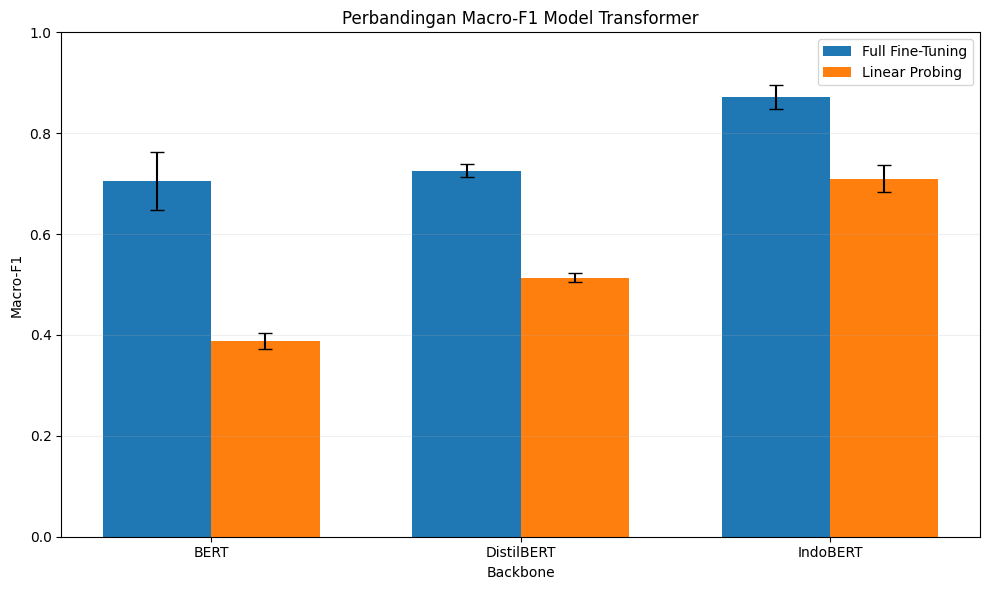

In [ ]:

backbones = ["BERT", "DistilBERT", "IndoBERT"]
strategies = ["full", "probing"]
labels = ["Full Fine-Tuning", "Linear Probing"]

x = np.arange(len(backbones))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

for i, strategy in enumerate(strategies):
    data = (
        rekap[rekap["strategy"] == strategy]
        .set_index("backbone")
        .loc[backbones]
    )

    ax.bar(
        x + (i - 0.5) * width,
        data["macro_f1_mean"],
        width,
        yerr=data["macro_f1_std"],
        capsize=5,
        label=labels[i]
    )

ax.set_title("Perbandingan Macro-F1 Model Transformer")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Backbone")
ax.set_xticks(x)
ax.set_xticklabels(backbones)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    "/content/grafik_studio3/macro_f1.png",
    dpi=300
)
plt.show()


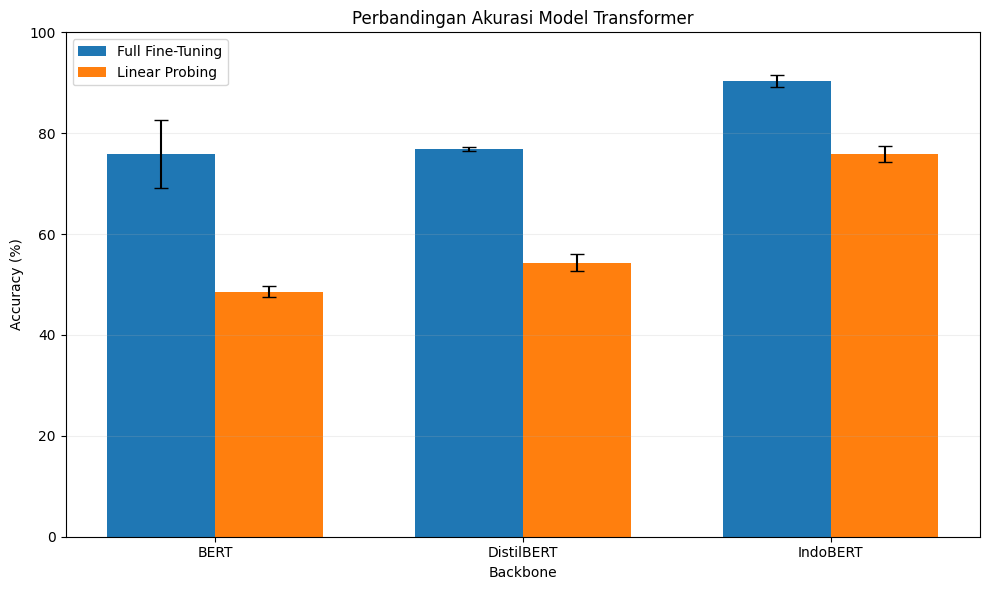

In [ ]:

fig, ax = plt.subplots(figsize=(10, 6))

for i, strategy in enumerate(strategies):
    data = (
        rekap[rekap["strategy"] == strategy]
        .set_index("backbone")
        .loc[backbones]
    )

    ax.bar(
        x + (i - 0.5) * width,
        data["accuracy_mean"] * 100,
        width,
        yerr=data["accuracy_std"] * 100,
        capsize=5,
        label=labels[i]
    )

ax.set_title("Perbandingan Akurasi Model Transformer")
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Backbone")
ax.set_xticks(x)
ax.set_xticklabels(backbones)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    "/content/grafik_studio3/accuracy.png",
    dpi=300
)
plt.show()


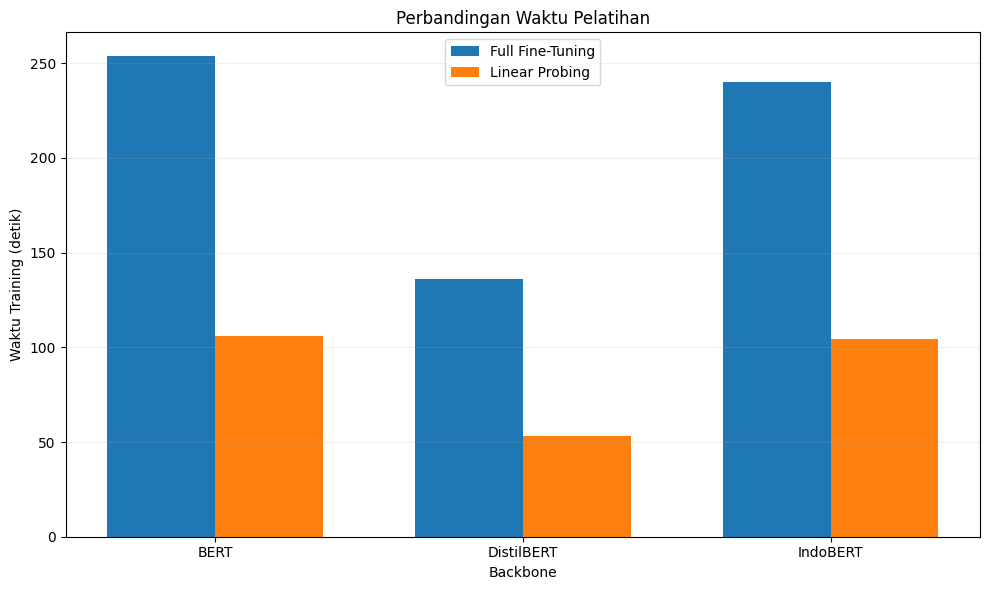

In [ ]:

fig, ax = plt.subplots(figsize=(10, 6))

for i, strategy in enumerate(strategies):
    data = (
        rekap[rekap["strategy"] == strategy]
        .set_index("backbone")
        .loc[backbones]
    )

    ax.bar(
        x + (i - 0.5) * width,
        data["training_time_mean"],
        width,
        label=labels[i]
    )

ax.set_title("Perbandingan Waktu Pelatihan")
ax.set_ylabel("Waktu Training (detik)")
ax.set_xlabel("Backbone")
ax.set_xticks(x)
ax.set_xticklabels(backbones)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    "/content/grafik_studio3/training_time.png",
    dpi=300
)
plt.show()


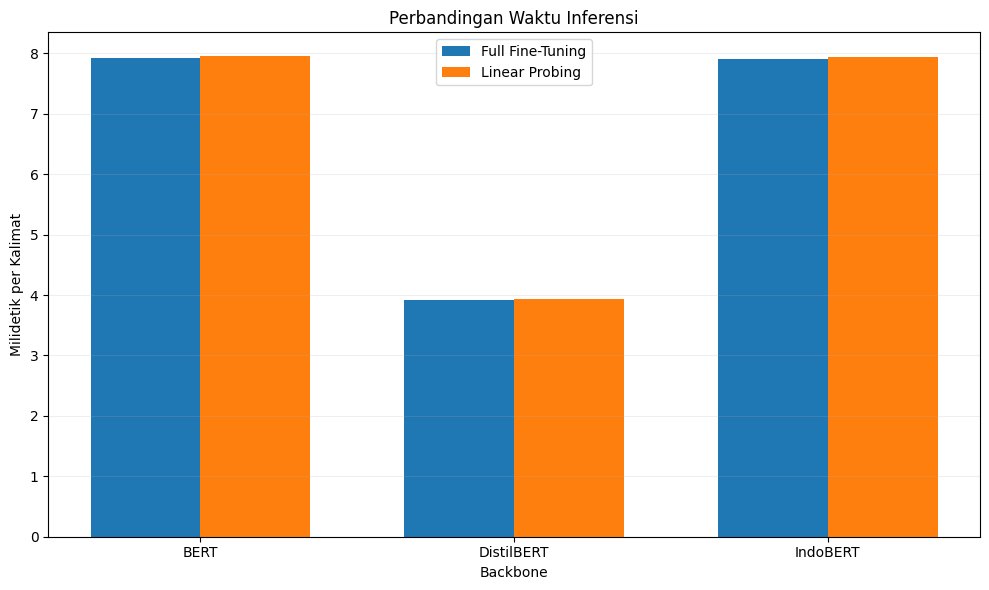

In [ ]:

fig, ax = plt.subplots(figsize=(10, 6))

for i, strategy in enumerate(strategies):
    data = (
        rekap[rekap["strategy"] == strategy]
        .set_index("backbone")
        .loc[backbones]
    )

    ax.bar(
        x + (i - 0.5) * width,
        data["inference_ms_mean"],
        width,
        label=labels[i]
    )

ax.set_title("Perbandingan Waktu Inferensi")
ax.set_ylabel("Milidetik per Kalimat")
ax.set_xlabel("Backbone")
ax.set_xticks(x)
ax.set_xticklabels(backbones)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    "/content/grafik_studio3/inference_time.png",
    dpi=300
)
plt.show()


In [ ]:

import shutil
from google.colab import files

shutil.make_archive(
    "/content/grafik_studio3",
    "zip",
    "/content/grafik_studio3"
)

files.download("/content/grafik_studio3.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>